In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

# 1. Create Mock Network Data (Packet Size, Network Speed, Connection Duration)
# 0 = Normal Traffic, 1 = Hacker Attack
mock_data = {
    'packet_size': [250, 240, 260, 900, 255, 950, 248, 910],
    'speed_mbps':  [100, 105, 98,  20,  102, 15,  99,  22],
    'duration_s':  [5,   6,   5,   45,  5,   50,  6,   42],
    'is_attack':   [0,   0,   0,   1,   0,   1,   0,   1]
}

df = pd.DataFrame(mock_data)

# 2. Train the Classical AI Model
X = df[['packet_size', 'speed_mbps', 'duration_s']] # Features
y = df['is_attack'] # Labels

classical_ai = LogisticRegression()
classical_ai.fit(X, y)

print("Classical AI Model Trained Successfully!")

# 3. Test the AI on a new, unseen network connection
new_connection = pd.DataFrame({'packet_size': [255], 'speed_mbps': [100], 'duration_s': [5]})
prediction = classical_ai.predict(new_connection)[0]

if prediction == 0:
    print("AI Analysis: Traffic looks NORMAL.")
else:
    print("AI Analysis: WARNING! Traffic looks SUSPICIOUS.")

Classical AI Model Trained Successfully!
AI Analysis: Traffic looks NORMAL.


In [1]:
from pathlib import Path
import pandas as pd

train_path = Path("KDDTrain+.txt")
print("File found:", train_path.exists())

if train_path.exists():
    train_df = pd.read_csv(train_path, header=None)
    print("Rows and columns:", train_df.shape)
    display(train_df.head(3))

File found: True
Rows and columns: (125973, 43)


,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [2]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
    "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files",
    "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df.columns = column_names
train_df["is_attack"] = (train_df["label"] != "normal").astype(int)

print("Normal = 0; attack = 1")
print(train_df["is_attack"].value_counts().rename(index={0: "Normal", 1: "Attack"}))
print("\nExample labels:")
print(train_df["label"].unique()[:10])

Normal = 0; attack = 1
is_attack
Normal    67343
Attack    58630
Name: count, dtype: int64

Example labels:
<StringArray>
[     'normal',     'neptune', 'warezclient',     'ipsweep',   'portsweep',
    'teardrop',        'nmap',       'satan',       'smurf',         'pod']
Length: 10, dtype: str


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# The three text-based columns
categorical_features = ["protocol_type", "service", "flag"]

# The remaining 38 traffic measurements are numeric
numeric_features = [
    name for name in column_names[:41]
    if name not in categorical_features
]

# Separate the input data from the answer labels
X_train = train_df.drop(columns=["label", "difficulty", "is_attack"])
y_train = train_df["is_attack"]

# Convert text categories to numbers and scale numeric measurements
preprocessor = ColumnTransformer([
    ("text", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numbers", StandardScaler(), numeric_features),
])

# Create and train the classifier
classical_ai = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000)
)

classical_ai.fit(X_train, y_train)

print("Training complete!")
print("Training records:", len(X_train))

Training complete!
Training records: 125973


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the separate test dataset using the same 43 column names
test_df = pd.read_csv(
    "KDDTest+.txt",
    header=None,
    names=column_names
)

# Convert labels to: 0 = normal, 1 = attack
y_test = (test_df["label"] != "normal").astype(int)

# Keep the same 41 input features used for training
X_test = test_df.drop(columns=["label", "difficulty"])

# Ask the trained model to classify the test records
predictions = classical_ai.predict(X_test)

print("Test records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Normal", "Attack"],
    zero_division=0
))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, predictions))

Test records: 22544
Accuracy: 0.7538

Classification report:
              precision    recall  f1-score   support

      Normal       0.65      0.93      0.76      9711
      Attack       0.92      0.62      0.74     12833

    accuracy                           0.75     22544
   macro avg       0.78      0.77      0.75     22544
weighted avg       0.80      0.75      0.75     22544

Confusion matrix (rows = actual, columns = predicted):
[[8991  720]
 [4830 8003]]


In [5]:
import random
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

number_of_qubits = 512
rng = random.Random(7)

# Alice chooses random bits and bases
alice_bits = [rng.randint(0, 1) for _ in range(number_of_qubits)]
alice_bases = [rng.choice(["Z", "X"]) for _ in range(number_of_qubits)]

# Bob independently chooses measurement bases
bob_bases = [rng.choice(["Z", "X"]) for _ in range(number_of_qubits)]

circuits = []

for i in range(number_of_qubits):
    circuit = QuantumCircuit(1, 1)

    # Alice prepares the bit
    if alice_bits[i] == 1:
        circuit.x(0)

    # Alice uses H to prepare in the X basis
    if alice_bases[i] == "X":
        circuit.h(0)

    # Bob uses H before measuring in the X basis
    if bob_bases[i] == "X":
        circuit.h(0)

    circuit.measure(0, 0)
    circuits.append(circuit)

simulator = AerSimulator()
result = simulator.run(circuits, shots=1, memory=True).result()

bob_bits = [
    int(result.get_memory(i)[0])
    for i in range(number_of_qubits)
]

# Keep only positions where Alice and Bob used the same basis
sifted = [
    i for i in range(number_of_qubits)
    if alice_bases[i] == bob_bases[i]
]

errors = sum(alice_bits[i] != bob_bits[i] for i in sifted)
qber = errors / len(sifted)

print("Qubits sent:", number_of_qubits)
print("Bits kept after sifting:", len(sifted))
print("Errors in sifted bits:", errors)
print(f"QBER: {qber:.1%}")

Qubits sent: 512
Bits kept after sifting: 259
Errors in sifted bits: 0
QBER: 0.0%


In [6]:
noise_probability = 0.10
noise_rng = random.Random(99)
noisy_circuits = []

for i in range(number_of_qubits):
    circuit = QuantumCircuit(1, 1)

    # Alice prepares the same bit and basis as in the clear run
    if alice_bits[i] == 1:
        circuit.x(0)
    if alice_bases[i] == "X":
        circuit.h(0)

    # Simulate channel noise: sometimes flip the qubit
    if noise_rng.random() < noise_probability:
        circuit.x(0)

    # Bob measures using the same basis choices as before
    if bob_bases[i] == "X":
        circuit.h(0)

    circuit.measure(0, 0)
    noisy_circuits.append(circuit)

noisy_result = simulator.run(
    noisy_circuits, shots=1, memory=True
).result()

bob_noisy_bits = [
    int(noisy_result.get_memory(i)[0])
    for i in range(number_of_qubits)
]

noisy_errors = sum(
    alice_bits[i] != bob_noisy_bits[i]
    for i in sifted
)
noisy_qber = noisy_errors / len(sifted)

print("Channel bit-flip probability:", f"{noise_probability:.0%}")
print("Bits kept after sifting:", len(sifted))
print("Errors in sifted bits:", noisy_errors)
print(f"Noisy-channel QBER: {noisy_qber:.1%}")

Channel bit-flip probability: 10%
Bits kept after sifting: 259
Errors in sifted bits: 13
Noisy-channel QBER: 5.0%


In [7]:
from qiskit import QuantumCircuit

eve_rng = random.Random(123)
eve_bases = [eve_rng.choice(["Z", "X"]) for _ in range(number_of_qubits)]
eve_circuits = []

for i in range(number_of_qubits):
    circuit = QuantumCircuit(1, 1)

    # Alice prepares her qubit
    if alice_bits[i] == 1:
        circuit.x(0)
    if alice_bases[i] == "X":
        circuit.h(0)

    # Eve measures in a random basis
    if eve_bases[i] == "X":
        circuit.h(0)
    circuit.measure(0, 0)

    # Eve sends a replacement qubit based on her measurement
    circuit.reset(0)
    with circuit.if_test((circuit.clbits[0], 1)):
        circuit.x(0)
    if eve_bases[i] == "X":
        circuit.h(0)

    # Bob measures in his chosen basis
    if bob_bases[i] == "X":
        circuit.h(0)
    circuit.measure(0, 0)

    eve_circuits.append(circuit)

eve_result = simulator.run(
    eve_circuits, shots=1, memory=True
).result()

bob_eve_bits = [
    int(eve_result.get_memory(i)[0])
    for i in range(number_of_qubits)
]

eve_errors = sum(
    alice_bits[i] != bob_eve_bits[i]
    for i in sifted
)
eve_qber = eve_errors / len(sifted)

print("Bits kept after sifting:", len(sifted))
print("Errors with Eve present:", eve_errors)
print(f"QBER with Eve present: {eve_qber:.1%}")

Bits kept after sifting: 259
Errors with Eve present: 59
QBER with Eve present: 22.8%


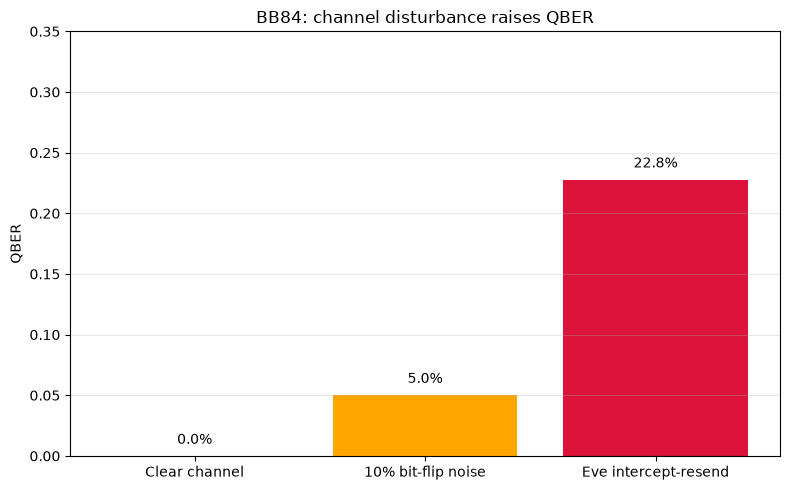

In [8]:
import matplotlib.pyplot as plt

scenarios = [
    "Clear channel",
    "10% bit-flip noise",
    "Eve intercept-resend"
]
qber_values = [qber, noisy_qber, eve_qber]

plt.figure(figsize=(8, 5))
bars = plt.bar(
    scenarios,
    qber_values,
    color=["seagreen", "orange", "crimson"]
)

plt.ylabel("QBER")
plt.title("BB84: channel disturbance raises QBER")
plt.ylim(0, 0.35)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, qber_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.1%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [9]:
def final_decision(network_prediction, qber_value):
    # The network model flags an attack
    if network_prediction == 1:
        return "REJECT"

    # Demo thresholds chosen to separate our three simulated results
    if qber_value >= 0.10:
        return "REJECT"
    if qber_value >= 0.03:
        return "MONITOR"

    return "ACCEPT"


# Pick a test record the model classified as normal
normal_index = next(
    i for i, value in enumerate(predictions)
    if int(value) == 0
)

network_prediction = int(predictions[normal_index])

# Show the decision for that same network prediction under each QBER scenario
decision_table = pd.DataFrame({
    "BB84 scenario": [
        "Clear channel",
        "10% bit-flip noise",
        "Eve intercept-resend"
    ],
    "QBER": [qber, noisy_qber, eve_qber],
})

decision_table["Final decision"] = [
    final_decision(network_prediction, value)
    for value in decision_table["QBER"]
]

print("Network model prediction: NORMAL")
display(decision_table)

Network model prediction: NORMAL


,BB84 scenario,QBER,Final decision
0,Clear channel,0.000000,ACCEPT
1,10% bit-flip noise,0.050193,MONITOR
2,Eve intercept-resend,0.227799,REJECT


In [10]:
import joblib

joblib.dump(classical_ai, "nsl_kdd_model.joblib")
print("Saved the trained model.")

Saved the trained model.
